# Итоги лабораторных работ №1–5: сравнение алгоритмов

В ноутбуке собраны результаты всех алгоритмов из лабораторных работ:

| ЛР | Алгоритм | Ноутбук |
|---|---|---|
| 1 | k ближайших соседей (KNN) | `lab1_knn.ipynb` |
| 2 | Логистическая / линейная регрессия | `lab2_linear.ipynb` |
| 3 | Решающее дерево | `lab3_decision_tree.ipynb` |
| 4 | Случайный лес | `lab4_random_forest.ipynb` |
| 5 | Градиентный бустинг | `lab5_gradient_boosting.ipynb` |

Для каждого алгоритма и каждой задачи есть четыре варианта:
* `sklearn baseline` — модель `sklearn` с параметрами по умолчанию (п. 2 задания);
* `sklearn improved` — улучшенный бейзлайн по результатам проверки гипотез (п. 3);
* `custom` — собственная реализация с параметрами бейзлайна (п. 4a–4d);
* `custom improved` — собственная реализация + техники улучшенного бейзлайна (п. 4e–4h).

Все метрики посчитаны на отложенной тестовой выборке, которая не использовалась ни для обучения, ни для подбора гиперпараметров. Задачи: **классификация** — исход матча Dota 2 по драфту (основная метрика ROC-AUC); **регрессия** — оценка позиции эндшпиля KRKPA7 (основная метрика R²).

Импортируем библиотеки и загружаем результаты, сохранённые каждым ноутбуком в `results/lab*.json`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from mllab.data import load_dota
from mllab.metrics import load_all_results

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

ALGORITHMS = ["KNN", "Linear", "DecisionTree", "RandomForest", "GradientBoosting"]
VARIANTS = ["sklearn baseline", "sklearn improved", "custom", "custom improved"]

results = load_all_results()
results["algorithm"] = pd.Categorical(results["algorithm"], ALGORITHMS, ordered=True)
results["variant"] = pd.Categorical(results["variant"], VARIANTS, ordered=True)
print("Загружено строк:", len(results), "| лабораторные:", sorted(results["lab"].unique()))

Загружено строк: 40 | лабораторные: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 1. Классификация (Dota 2)

Полная таблица метрик: строки — алгоритмы, столбцы — варианты. ROC-AUC — основная метрика.

In [2]:
cls = results[results.task == "classification"]

def metric_table(frame, metric):
    return frame.pivot_table(index="algorithm", columns="variant", values=metric, observed=False)

for metric in ["roc_auc", "accuracy", "f1"]:
    print(metric.upper())
    display(metric_table(cls, metric))

ROC_AUC


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.5273,0.6384,0.5273,0.6384
Linear,0.6342,0.6395,0.6342,0.6395
DecisionTree,0.5181,0.6368,0.5214,0.6378
RandomForest,0.6087,0.6387,0.6069,0.6387
GradientBoosting,0.6118,0.6385,0.6118,0.6387


ACCURACY


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.5278,0.5974,0.5278,0.5974
Linear,0.5979,0.5988,0.5977,0.5986
DecisionTree,0.5193,0.5966,0.5222,0.5951
RandomForest,0.5786,0.5984,0.5778,0.5989
GradientBoosting,0.5814,0.5969,0.5814,0.5963


F1


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.5640,0.6353,0.5640,0.6353
Linear,0.6399,0.6392,0.6399,0.6392
DecisionTree,0.5435,0.6403,0.5445,0.6274
RandomForest,0.6374,0.6356,0.6275,0.6362
GradientBoosting,0.6559,0.6353,0.6559,0.6348


Визуализируем ROC-AUC всех вариантов всех алгоритмов. Пунктиром отмечен уровень случайного угадывания (0.5).

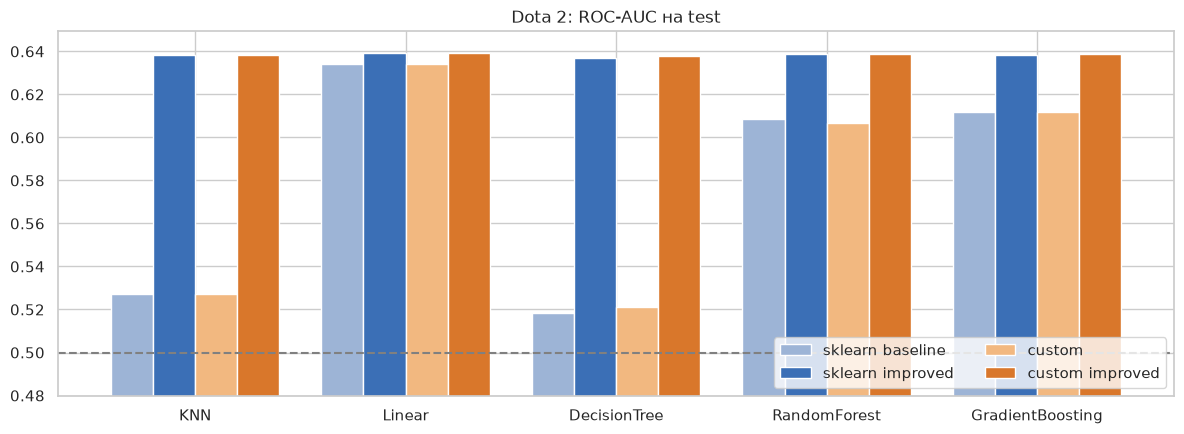

In [3]:
def plot_metric(frame, metric, title, lower):
    table = metric_table(frame, metric)
    ax = table.plot.bar(figsize=(12, 4.5), width=0.8, color=["#9db4d6", "#3b6fb6", "#f2b880", "#d9772b"])
    ax.set_ylim(lower, table.max().max() + 0.01)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(loc="lower right", ncol=2)
    return ax

ax = plot_metric(cls, "roc_auc", "Dota 2: ROC-AUC на test", 0.48)
ax.axhline(0.5, color="grey", ls="--")
plt.tight_layout()

Оценим статистическую погрешность ROC-AUC на тестовой выборке Dota 2 по формуле Хэнли — Макнила: это помогает понять, какие различия между моделями значимы.

In [4]:
def auc_standard_error(auc, n_pos, n_neg):
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc ** 2) + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg))

_, _, _, y_dota_test = load_dota()
n_pos, n_neg = int(y_dota_test.sum()), int((1 - y_dota_test).sum())
print(f"Тест: {n_pos} побед команды 1, {n_neg} побед команды 2")
print(f"Стандартная ошибка ROC-AUC при AUC≈0.64: {auc_standard_error(0.64, n_pos, n_neg):.4f}")

Тест: 5502 побед команды 1, 4792 побед команды 2
Стандартная ошибка ROC-AUC при AUC≈0.64: 0.0054


<!-- summary_cls -->
**Выводы по классификации (Dota 2).**
* **Бейзлайны сильно различаются**, и порядок отражает индуктивное смещение алгоритмов: логистическая регрессия (0.634) > градиентный бустинг (0.612) > случайный лес (0.609) ≫ KNN (0.527) ≈ дерево (0.518). Аддитивная линейная модель естественно описывает «сумму сил героев», а KNN и полное дерево на разреженных шумных признаках практически не обобщают — их бейзлайны хуже константного прогноза по accuracy.
* **После улучшений все пять алгоритмов сходятся к ROC-AUC 0.637–0.640.** Разброс между ними (0.003) меньше стандартной ошибки ROC-AUC на тесте (≈0.005), т. е. модели статистически неразличимы. Потолок задачи определяется информацией, содержащейся в драфте, а не выбором алгоритма; accuracy ≈ 0.60 — исход матча лишь частично предопределён составом героев.
* **Главный рычаг — признаки**, а не алгоритм: статистики драфта (win rate, синергия, контрпики) дали основной прирост KNN, деревьям и ансамблям; для логистической регрессии — синергия и контрпики, которые она не может получить из индикаторов сама.
* **Лучшая модель для практического применения — логистическая регрессия** на индикаторах героев + синергия/контрпики (ROC-AUC 0.6395): формально лучшая, обучается за секунды и интерпретируема (коэффициент = вклад героя).

## 2. Регрессия (шахматный эндшпиль KRKPA7)

Полная таблица метрик. R² — основная метрика; для RMSE и MAE меньше — лучше.

In [5]:
reg = results[results.task == "regression"]
for metric in ["r2", "rmse", "mae"]:
    print(metric.upper())
    display(metric_table(reg, metric))

R2


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.8269,0.9829,0.8161,0.9830
Linear,0.6420,0.9206,0.6420,0.9206
DecisionTree,0.9875,0.9843,0.9875,0.9843
RandomForest,0.9864,0.9872,0.9890,0.9890
GradientBoosting,0.8697,0.9840,0.8697,0.9834


RMSE


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.2078,0.0652,0.2142,0.0651
Linear,0.2989,0.1407,0.2989,0.1407
DecisionTree,0.0559,0.0625,0.0559,0.0625
RandomForest,0.0583,0.0566,0.0523,0.0523
GradientBoosting,0.1803,0.0631,0.1803,0.0645


MAE


variant,sklearn baseline,sklearn improved,custom,custom improved
algorithm,,,,
KNN,0.1172,0.0063,0.1219,0.0062
Linear,0.2583,0.0816,0.2583,0.0816
DecisionTree,0.0031,0.0047,0.0031,0.0047
RandomForest,0.0095,0.0090,0.0080,0.0080
GradientBoosting,0.1171,0.0127,0.1171,0.0137


Визуализируем R² всех вариантов всех алгоритмов.

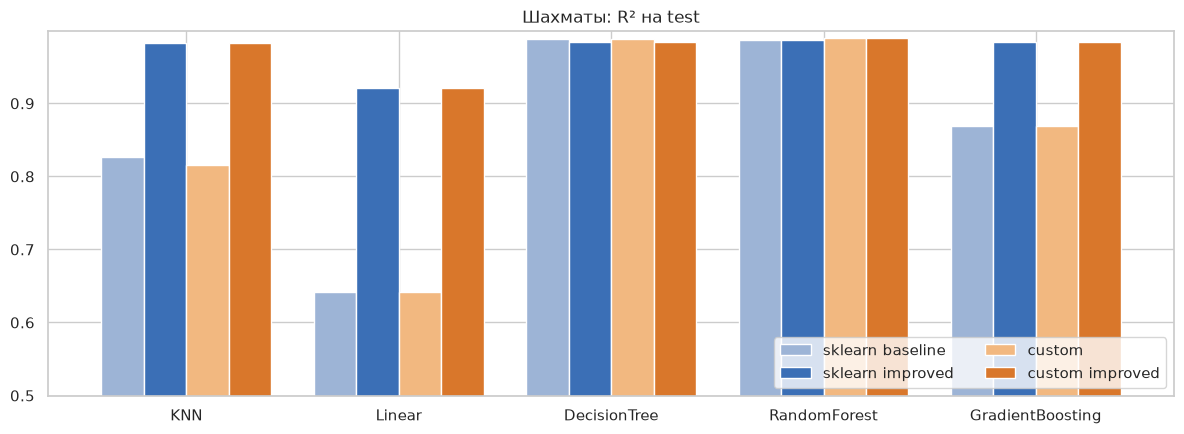

In [6]:
plot_metric(reg, "r2", "Шахматы: R² на test", 0.5)
plt.tight_layout()

<!-- summary_reg -->
**Выводы по регрессии (шахматы KRKPA7).**
* **Деревья и ансамбли деревьев — лучшие модели:** случайный лес (R² 0.986–0.989), одиночное дерево (0.984–0.988), бустинг после настройки (0.983–0.984), а также KNN со взвешиванием признаков (0.983). Различия между ними ≈ 0.005 R², что на 640 тестовых позициях соответствует 1–2 ошибочно оценённым позициям, — в пределах шума.
* **Линейная модель — самая слабая** даже после улучшений (R² 0.921): попарные взаимодействия покрывают только конъюнкции двух условий, а правила эндшпиля глубже (дерево использует до 13 последовательных условий).
* Для дерева и леса бейзлайн уже был оптимален (улучшения не дали значимого эффекта), а для линейной модели, KNN и бустинга улучшения критичны: +0.28, +0.16 и +0.11 R² соответственно.
* **Лучшая модель для практического применения — решающее дерево:** R² 0.9875 при всего 46 листьях — компактная и полностью интерпретируемая оценочная функция эндшпиля (набор правил «если … то …»); если важнее точность, чем интерпретируемость, — случайный лес.

## 3. Эффект улучшения бейзлайна

Прирост основной метрики от техник улучшенного бейзлайна для `sklearn` и для собственных реализаций, а также разница между собственной реализацией и `sklearn` в одинаковых условиях.

In [7]:
def gains(frame, metric):
    t = metric_table(frame, metric)
    return pd.DataFrame({
        "improved − baseline (sklearn)": t["sklearn improved"] - t["sklearn baseline"],
        "improved − baseline (custom)": t["custom improved"] - t["custom"],
        "custom − sklearn (baseline)": t["custom"] - t["sklearn baseline"],
        "custom − sklearn (improved)": t["custom improved"] - t["sklearn improved"],
    })

print("Классификация, ΔROC-AUC")
display(gains(cls, "roc_auc"))
print("Регрессия, ΔR²")
display(gains(reg, "r2"))

Классификация, ΔROC-AUC


,improved − baseline (sklearn),improved − baseline (custom),custom − sklearn (baseline),custom − sklearn (improved)
algorithm,,,,
KNN,0.1111,0.1111,0.0000,0.0000
Linear,0.0053,0.0053,-0.0000,-0.0000
DecisionTree,0.1187,0.1164,0.0032,0.0010
RandomForest,0.0300,0.0318,-0.0018,-0.0000
GradientBoosting,0.0267,0.0268,-0.0000,0.0002


Регрессия, ΔR²


,improved − baseline (sklearn),improved − baseline (custom),custom − sklearn (baseline),custom − sklearn (improved)
algorithm,,,,
KNN,0.1560,0.1669,-0.0108,0.0001
Linear,0.2787,0.2787,0.0000,-0.0000
DecisionTree,-0.0031,-0.0031,0.0000,0.0000
RandomForest,0.0008,0.0000,0.0026,0.0019
GradientBoosting,0.1144,0.1137,0.0000,-0.0007


<!-- summary_gains -->
**Выводы по эффекту улучшений и собственным реализациям.**
* Приросты от техник улучшенного бейзлайна у собственных реализаций практически такие же, как у `sklearn` (столбцы 1 и 2 отличаются не больше чем на 0.011): техники (признаки, гиперпараметры) переносятся между реализациями без изменений.
* Собственные реализации совпадают с `sklearn` по качеству: точно — линейные модели и бустинг (до машинной точности на дискретных признаках) и KNN (кроме выбора среди равноудалённых соседей на бинарных шахматных признаках, −0.011 R²); дерево — с точностью до разрешения равенств и квантования порогов (≤ 0.003 ROC-AUC); случайный лес — в пределах разброса по seed.

## 4. Время обучения

Сравниваем время обучения (в секундах, логарифмическая шкала) `sklearn` и собственных реализаций. Для KNN основное время — предсказание, поэтому показываем сумму обучения и предсказания.

variant                          sklearn baseline  sklearn improved  custom  \
task           algorithm                                                      
classification KNN                        11.8315            7.2584 16.6220   
               Linear                     29.5856            1.5324  2.1459   
               DecisionTree                3.2594            0.8923  5.4922   
               RandomForest                4.1121            4.3562 48.9680   
               GradientBoosting           16.6782           33.7916 28.5276   
regression     KNN                         0.1836            0.2213  0.0466   
               Linear                      0.1349            0.4187  0.0754   
               DecisionTree                0.0126            0.0274  0.0091   
               RandomForest                0.3070            0.7321  0.2872   
               GradientBoosting            0.2528            1.7370  0.2195   

variant                          custom improved  
task           algorithm                          
classification KNN                       17.8542  
               Linear                     3.8063  
               DecisionTree               0.2847  
               RandomForest               3.5077  
               GradientBoosting           4.9051  
regression     KNN                        6.4634  
               Linear                     1.4615  
               DecisionTree               0.0290  
               RandomForest               0.4583  
               GradientBoosting           4.3387

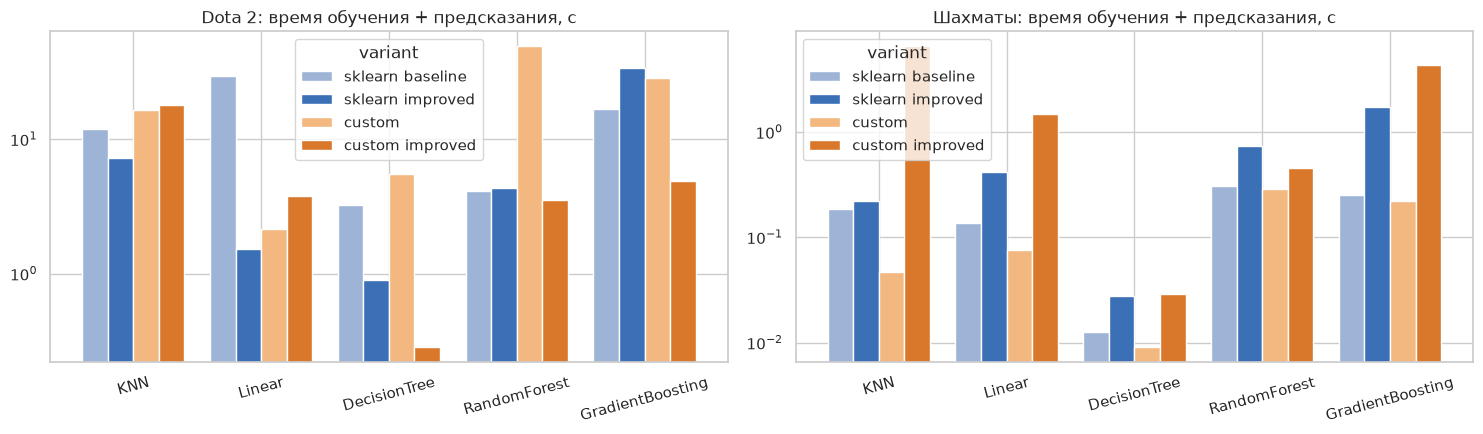

In [8]:
results["total_time"] = results["fit_time"] + results["predict_time"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, task, title in zip(axes, ["classification", "regression"], ["Dota 2", "Шахматы"]):
    t = results[results.task == task].pivot_table(index="algorithm", columns="variant", values="total_time",
                                                  observed=False)
    t.plot.bar(ax=ax, logy=True, width=0.8, color=["#9db4d6", "#3b6fb6", "#f2b880", "#d9772b"])
    ax.set_title(f"{title}: время обучения + предсказания, с")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
results.pivot_table(index=["task", "algorithm"], columns="variant", values="total_time", observed=False)

<!-- summary_time -->
**Выводы по времени.** Замеры сделаны на 16-ядерном CPU; часть ноутбуков выполнялась параллельно, поэтому абсолютные значения приблизительны (например, у бейзлайна логистической регрессии), но соотношения показательны:
* KNN тратит время на предсказание, а не на обучение (≈7–18 с на 10 тыс. матчей против долей секунды у остальных моделей).
* Собственные деревья медленнее `sklearn` там, где узлов очень много (полный лес на Dota 2: 49 с против 4 с — цикл Python против Cython), и быстрее на неглубоких деревьях с непрерывными признаками благодаря гистограммам (бустинг: 4.9 с против 34 с, дерево: 0.28 с против 0.89 с).
* Метод Ньютона в собственной логистической регрессии не чувствителен к масштабу признаков и на сырых данных обучается быстрее `lbfgs`.
* В улучшенных конвейерах для Dota 2 признаки драфта берутся из дискового кэша после подбора гиперпараметров, поэтому время отражает только обучение модели (генерация признаков занимает ≈5–7 с).

## 5. Рейтинг моделей

Все 20 моделей для каждой задачи, отсортированные по основной метрике.

In [9]:
cols_cls = ["algorithm", "variant", "roc_auc", "accuracy", "f1", "fit_time"]
cols_reg = ["algorithm", "variant", "r2", "rmse", "mae", "fit_time"]
display(cls.sort_values("roc_auc", ascending=False)[cols_cls].reset_index(drop=True).head(10))
display(reg.sort_values("r2", ascending=False)[cols_reg].reset_index(drop=True).head(10))

,algorithm,variant,roc_auc,accuracy,f1,fit_time
0,Linear,sklearn improved,0.6395,0.5988,0.6392,1.3509
1,Linear,custom improved,0.6395,0.5986,0.6392,3.6558
2,RandomForest,sklearn improved,0.6387,0.5984,0.6356,4.1057
3,RandomForest,custom improved,0.6387,0.5989,0.6362,3.0625
4,GradientBoosting,custom improved,0.6387,0.5963,0.6348,4.7719
5,GradientBoosting,sklearn improved,0.6385,0.5969,0.6353,33.7252
6,KNN,custom improved,0.6384,0.5974,0.6353,0.2429
7,KNN,sklearn improved,0.6384,0.5974,0.6353,0.1685
8,DecisionTree,custom improved,0.6378,0.5951,0.6274,0.1903
9,DecisionTree,sklearn improved,0.6368,0.5966,0.6403,0.8094


,algorithm,variant,r2,rmse,mae,fit_time
0,RandomForest,custom improved,0.9890,0.0523,0.0080,0.4189
1,RandomForest,custom,0.9890,0.0523,0.0080,0.2578
2,DecisionTree,sklearn baseline,0.9875,0.0559,0.0031,0.0099
3,DecisionTree,custom,0.9875,0.0559,0.0031,0.0074
4,RandomForest,sklearn improved,0.9872,0.0566,0.0090,0.5898
5,RandomForest,sklearn baseline,0.9864,0.0583,0.0095,0.2475
6,DecisionTree,custom improved,0.9843,0.0625,0.0047,0.0271
7,DecisionTree,sklearn improved,0.9843,0.0625,0.0047,0.0218
8,GradientBoosting,sklearn improved,0.9840,0.0631,0.0127,1.7218
9,GradientBoosting,custom improved,0.9834,0.0645,0.0137,4.2821


<!-- summary_final -->
## Общие выводы

1. **Классификация (Dota 2):** после улучшений все алгоритмы достигают ROC-AUC 0.637–0.640 и accuracy ≈ 0.60; различия между ними статистически незначимы. Лучшая модель — **логистическая регрессия** с признаками синергии и контрпиков (ROC-AUC 0.6395): простая, быстрая и интерпретируемая. Ключевой фактор качества — инженерия признаков драфта, а не выбор алгоритма.
2. **Регрессия (шахматы KRKPA7):** лучшие модели — **случайный лес** (R² до 0.989) и **решающее дерево** (0.9875, 46 правил); KNN со взвешиванием признаков и настроенный бустинг практически не уступают (0.983–0.984), линейная модель отстаёт (0.921).
3. **Характер данных определяет, какие гипотезы работают.** На шумной задаче (Dota 2) помогает регуляризация: большое k у KNN, крупные листья у деревьев и леса, неглубокие деревья и малый темп обучения у бустинга. На детерминированной логической задаче (шахматы) нужна максимальная выразительность: полные деревья, глубокий бустинг, малое k у KNN после взвешивания признаков.
4. **Параметры по умолчанию не универсальны:** один и тот же бустинг недообучен на шахматах и переобучается на Dota 2 при увеличении числа итераций; полное дерево — лучшая модель для шахмат и худшая для Dota 2.
5. **Собственные реализации** всех пяти алгоритмов воспроизводят качество `sklearn` и дают такой же прирост от техник улучшенного бейзлайна, что подтверждает корректность как реализаций, так и выводов о гипотезах.